In [ ]:
### 크롤링 코드 실행 ###

import time
import pandas as pd
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By

# 1. Chrome 설정 (창이 보이도록 headless 옵션 제외)
options = Options()
options.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36")

driver = webdriver.Chrome(options=options)

# 2. 페이지 접속
url = "https://pokemondb.net/pokedex/all"
driver.get(url)
time.sleep(2)  # 페이지 로딩 대기

# 3. 테이블 데이터 추출
rows = driver.find_elements(By.CSS_SELECTOR, "table#pokedex tbody tr")
data = []

for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    
    dex_num = cols[0].text.strip()
    
    name_parts = cols[1].text.strip().split("\n")
    name = name_parts[-1] if len(name_parts) > 1 else name_parts[0]
    
    type_links = cols[2].find_elements(By.TAG_NAME, "a")
    type1 = type_links[0].text.strip()
    type2 = type_links[1].text.strip() if len(type_links) > 1 else None
    
    total = int(cols[3].text.strip())
    hp = int(cols[4].text.strip())
    attack = int(cols[5].text.strip())
    defense = int(cols[6].text.strip())
    sp_atk = int(cols[7].text.strip())
    sp_def = int(cols[8].text.strip())
    speed = int(cols[9].text.strip())
    
    data.append([dex_num, name, type1, type2, total, hp, attack, defense, sp_atk, sp_def, speed])

driver.quit()

# 4. DataFrame 변환 및 CSV 파일 저장
columns = ["Dex_Num", "Name", "Type1", "Type2", "Total", "HP", "Attack", "Defense", "Sp_Atk", "Sp_Def", "Speed"]
df = pd.DataFrame(data, columns=columns)
df.to_csv("pokemon.csv", index=False, encoding="utf-8-sig")

print(f"수집 완료: 총 {len(df)}개 데이터 저장됨")
print(df.head())

수집 완료: 총 1261개 데이터 저장됨
  Dex_Num           Name  Type1   Type2  Total  HP  Attack  Defense  Sp_Atk  \
0    0001      Bulbasaur  GRASS  POISON    318  45      49       49      65   
1    0002        Ivysaur  GRASS  POISON    405  60      62       63      80   
2    0003       Venusaur  GRASS  POISON    525  80      82       83     100   
3    0003  Mega Venusaur  GRASS  POISON    625  80     100      123     122   
4    0004     Charmander   FIRE     NaN    309  39      52       43      60   

   Sp_Def  Speed  
0      65     45  
1      80     60  
2     100     80  
3     120     80  
4      50     65  


2026-11-16 13:09:08,232 [WARNING] Matplotlib is building the font cache; this may take a moment.
2026-11-16 13:10:21,486 [INFO] Failed to extract font properties from /System/Library/Fonts/Supplemental/NISC18030.ttf: Non-scalable fonts are not supported
2026-11-16 13:10:22,920 [INFO] Failed to extract font properties from /System/Library/Fonts/Apple Color Emoji.ttc: Non-scalable fonts are not supported
2026-11-16 13:10:24,657 [INFO] Failed to extract font properties from /System/Library/Fonts/LastResort.otf: tuple indices must be integers or slices, not str
2026-11-16 13:10:25,513 [INFO] generated new fontManager


분석 대상 포켓몬 수: Balanced 152마리, Extreme 152마리

=== 그룹별 평균 비교 ===
             Total  Stat_Std  Win_Rate
Type_Group                            
Balanced    532.92     15.19     42.99
Extreme     536.33     40.31     57.34

=== 전체 승률 TOP 5 포켓몬 ===
          Name Type_Group  Total  Stat_Std   Win_Rate
     Glastrier    Extreme    580 42.622373 100.000000
      Zen Mode    Extreme    540 40.000000 100.000000
    Iron Hands    Extreme    570 45.725267 100.000000
      Ursaluna    Extreme    550 40.083247  99.342105
Mega Heracross    Extreme    600 49.193496  99.342105


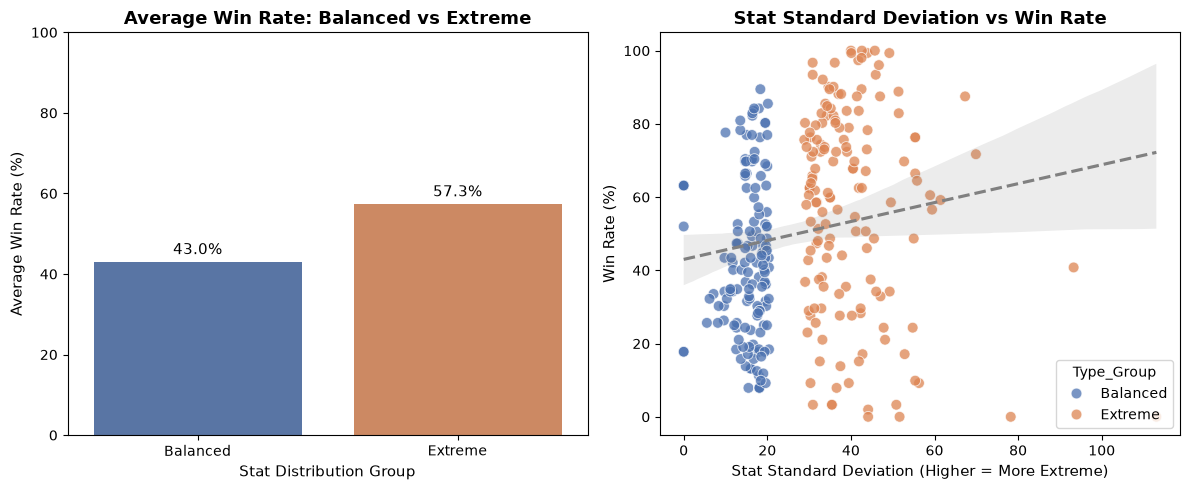

In [ ]:
### 밸런스형 vs 극단형 분류 → 1:1 대결 시뮬레이션 → 승률 비교 그래프 출력 ###

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 불러오기 및 체급(Total) 통일
df = pd.read_csv("pokemon.csv")

# 공정한 비교를 위해 총합 능력치(Total)가 480~600 사이인 주요 포켓몬만 필터링
df = df[(df["Total"] >= 480) & (df["Total"] <= 600)].copy()

# 2. 밸런스형(Balanced) vs 극단형(Extreme) 분류
stat_cols = ["HP", "Attack", "Defense", "Sp_Atk", "Sp_Def", "Speed"]
df["Stat_Std"] = df[stat_cols].std(axis=1)  # 6가지 능력치의 표준편차 계산

q30 = df["Stat_Std"].quantile(0.30)  # 표준편차 하위 30% 기준 (고른 능력치)
q70 = df["Stat_Std"].quantile(0.70)  # 표준편차 상위 30% 기준 (치우친 능력치)

def classify_group(std):
    if std <= q30:
        return "Balanced"
    elif std >= q70:
        return "Extreme"
    return "Middle"

df["Type_Group"] = df["Stat_Std"].apply(classify_group)
target_df = df[df["Type_Group"].isin(["Balanced", "Extreme"])].copy().reset_index(drop=True)

print(f"분석 대상 포켓몬 수: Balanced {sum(target_df['Type_Group']=='Balanced')}마리, Extreme {sum(target_df['Type_Group']=='Extreme')}마리\n")

# 3. 1:1 대결 시뮬레이션 함수
def simulate_battle(p1, p2):
    hp1, hp2 = p1["HP"], p2["HP"]
    
    # 주력 공격(물리/특수 중 높은 값)과 상대 대응 방어 기반 1턴당 데미지 계산
    dmg1 = (p1["Attack"] / p2["Defense"]) * 20 if p1["Attack"] >= p1["Sp_Atk"] else (p1["Sp_Atk"] / p2["Sp_Def"]) * 20
    dmg2 = (p2["Attack"] / p1["Defense"]) * 20 if p2["Attack"] >= p2["Sp_Atk"] else (p2["Sp_Atk"] / p1["Sp_Def"]) * 20
    
    # 스피드 기반 선공 결정
    p1_first = p1["Speed"] >= p2["Speed"]
    
    while hp1 > 0 and hp2 > 0:
        if p1_first:
            hp2 -= dmg1
            if hp2 <= 0:
                return 1
            hp1 -= dmg2
            if hp1 <= 0:
                return 0
        else:
            hp1 -= dmg2
            if hp1 <= 0:
                return 0
            hp2 -= dmg1
            if hp2 <= 0:
                return 1

# 모든 Balanced 포켓몬 vs 모든 Extreme 포켓몬 교차 대결 실행
records = target_df.to_dict("records")
win_rates = []

for i, p1 in enumerate(records):
    wins = 0
    matches = 0
    for j, p2 in enumerate(records):
        if i != j and p1["Type_Group"] != p2["Type_Group"]:
            wins += simulate_battle(p1, p2)
            matches += 1
    win_rates.append((wins / matches) * 100)

target_df["Win_Rate"] = win_rates

# 4. 통계 결과 출력
summary = target_df.groupby("Type_Group")[["Total", "Stat_Std", "Win_Rate"]].mean().round(2)
print("=== 그룹별 평균 비교 ===")
print(summary)
print("\n=== 전체 승률 TOP 5 포켓몬 ===")
print(target_df.sort_values(by="Win_Rate", ascending=False)[["Name", "Type_Group", "Total", "Stat_Std", "Win_Rate"]].head(5).to_string(index=False))

# 5. 결과 시각화 (막대그래프 + 산점도)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 그래프 1: 그룹별 평균 승률 비교 막대그래프
sns.barplot(
    data=target_df, x="Type_Group", y="Win_Rate",
    hue="Type_Group", palette=["#4C72B0", "#DD8452"],
    errorbar=None, legend=False, ax=axes[0]
)
axes[0].set_title("Average Win Rate: Balanced vs Extreme", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Stat Distribution Group", fontsize=11)
axes[0].set_ylabel("Average Win Rate (%)", fontsize=11)
axes[0].set_ylim(0, 100)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=11)

# 그래프 2: 능력치 표준편차(극단성)와 승률의 상관관계 산점도
sns.scatterplot(
    data=target_df, x="Stat_Std", y="Win_Rate",
    hue="Type_Group", palette=["#4C72B0", "#DD8452"],
    alpha=0.75, s=60, ax=axes[1]
)
sns.regplot(
    data=target_df, x="Stat_Std", y="Win_Rate",
    scatter=False, color="gray", line_kws={"linestyle": "--"}, ax=axes[1]
)
axes[1].set_title("Stat Standard Deviation vs Win Rate", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Stat Standard Deviation (Higher = More Extreme)", fontsize=11)
axes[1].set_ylabel("Win Rate (%)", fontsize=11)

plt.tight_layout()
plt.savefig("battle_result.png", dpi=150)  # 보고서 첨부용 이미지 자동 저장
plt.show()

In [9]:
### 밸런스형 / 극단형 포켓몬 영문 목록 확인 ###

import pandas as pd

# 1. 데이터 불러오기 및 동일 기준 필터링
df = pd.read_csv("pokemon.csv")
df = df[(df["Total"] >= 480) & (df["Total"] <= 600)].copy()

stat_cols = ["HP", "Attack", "Defense", "Sp_Atk", "Sp_Def", "Speed"]
df["Stat_Std"] = df[stat_cols].std(axis=1)

q30 = df["Stat_Std"].quantile(0.30)
q70 = df["Stat_Std"].quantile(0.70)

# 2. 표준편차 기준 정렬 (가장 고른 순서 / 가장 극단적인 순서)
balanced_df = df[df["Stat_Std"] <= q30].sort_values(by="Stat_Std", ascending=True)
extreme_df = df[df["Stat_Std"] >= q70].sort_values(by="Stat_Std", ascending=False)

print("=== 대표 밸런스형(Balanced) 포켓몬 TOP 10 ===")
print(balanced_df[["Name", "Type1", "Total", "Stat_Std"] + stat_cols].head(10).to_string(index=False))

print("\n=== 대표 극단형(Extreme) 포켓몬 TOP 10 ===")
print(extreme_df[["Name", "Type1", "Total", "Stat_Std"] + stat_cols].head(10).to_string(index=False))

# 전체 영문 이름 리스트가 필요할 경우 아래 주석 해제
# print("\n[전체 Balanced 영문 목록]:", balanced_df["Name"].tolist())
# print("\n[전체 Extreme 영문 목록]:", extreme_df["Name"].tolist())

=== 대표 밸런스형(Balanced) 포켓몬 TOP 10 ===
      Name   Type1  Total  Stat_Std  HP  Attack  Defense  Sp_Atk  Sp_Def  Speed
       Mew PSYCHIC    600  0.000000 100     100      100     100     100    100
   Jirachi   STEEL    600  0.000000 100     100      100     100     100    100
    Glalie     ICE    480  0.000000  80      80       80      80      80     80
    Celebi PSYCHIC    600  0.000000 100     100      100     100     100    100
    Phione   WATER    480  0.000000  80      80       80      80      80     80
   Manaphy   WATER    600  0.000000 100     100      100     100     100    100
Land Forme   GRASS    600  0.000000 100     100      100     100     100    100
   Victini PSYCHIC    600  0.000000 100     100      100     100     100    100
  Silvally  NORMAL    570  0.000000  95      95       95      95      95     95
  Slurpuff   FAIRY    480  5.549775  82      80       86      85      75     72

=== 대표 극단형(Extreme) 포켓몬 TOP 10 ===
           Name   Type1  Total   Stat_Std  HP  

[Balanced] Mew: Because it can use all kinds of moves, many scientists believe Mew to be the ancestor of Pokémon.

[Balanced] Jirachi: It is said to wake up for just seven days every 1,000 years and use its power to grant any wish.

[Balanced] Glalie: It prevents prey from escaping by instantaneously freezing moisture in the air.

[Balanced] Celebi: It has the power to travel across time, but it is said to appear only in peaceful times.

[Balanced] Phione: Can be seen floating offshore during seasons when the seas are warm. Its azure body blends in with the ocean waters—logic suggests this is a defense mechanism against natural predators.

[Extreme] Shuckle: It stores berries in its shell. The berries mix with its body fluids to become delicious juices.

[Extreme] Blissey: The eggs it lays are filled with happiness. Eating even one bite will bring a smile to anyone.

[Extreme] Deoxys (Attack Forme): An alien virus that fell to earth on a meteorite underwent a DNA mutation to become thi

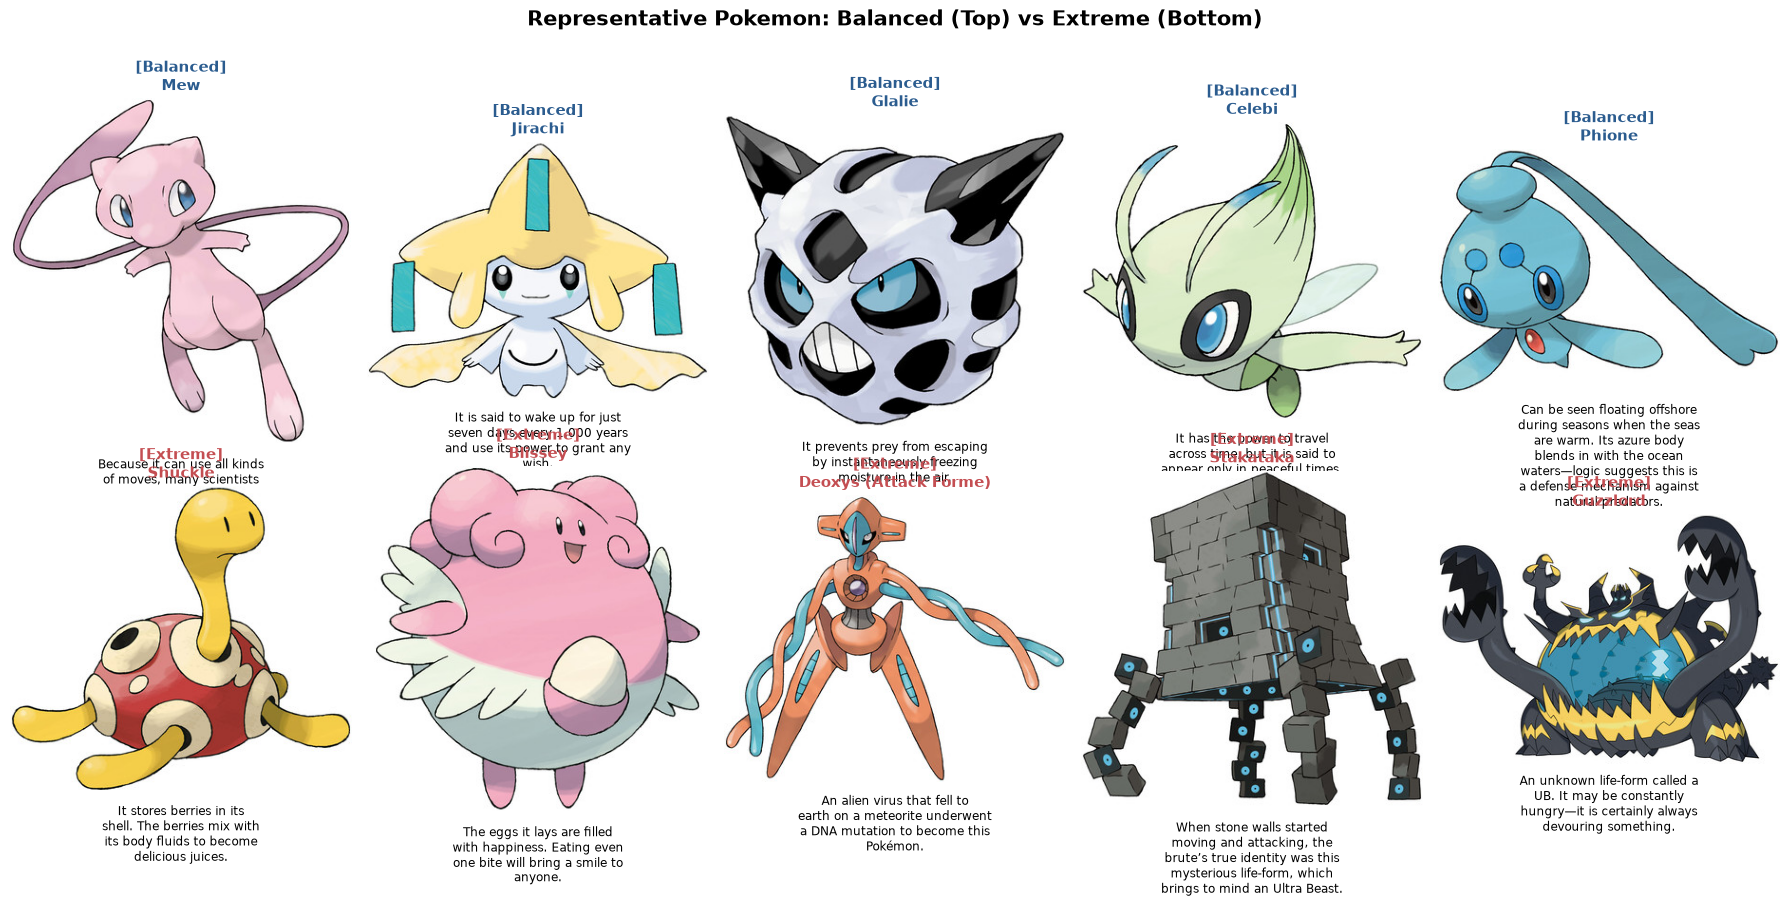

In [12]:
### 영문 포켓몬 설명(Pokédex Entries) 및 포켓몬 사진 크롤링 ###

import os
import ssl
import time
import textwrap
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By

# macOS Python SSL 인증서 오류 해결 설정
ssl_context = ssl._create_unverified_context()

# 1. 수집할 대표 포켓몬 목록 (그룹, 표기명, URL 슬러그)
targets = [
    ("Balanced", "Mew", "mew"),
    ("Balanced", "Jirachi", "jirachi"),
    ("Balanced", "Glalie", "glalie"),
    ("Balanced", "Celebi", "celebi"),
    ("Balanced", "Phione", "phione"),
    ("Extreme", "Shuckle", "shuckle"),
    ("Extreme", "Blissey", "blissey"),
    ("Extreme", "Deoxys (Attack Forme)", "deoxys"),
    ("Extreme", "Stakataka", "stakataka"),
    ("Extreme", "Guzzlord", "guzzlord"),
]

os.makedirs("pokemon_images", exist_ok=True)

# 2. Chrome 설정 (eager 전략으로 광고 로딩 대기 차단)
options = Options()
options.page_load_strategy = "eager"
options.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36")

driver = webdriver.Chrome(options=options)
driver.set_page_load_timeout(15)

results = []

for group, name, slug in targets:
    url = f"https://pokemondb.net/pokedex/{slug}"
    try:
        driver.get(url)
    except Exception:
        driver.execute_script("window.stop();")
    
    time.sleep(1.2)  # 상단 포켓몬 사진이 화면에 보이도록 잠시 대기
    
    # ① 포켓몬 공식 일러스트(사진) URL 추출 및 이미지 파일 저장
    img_element = driver.find_element(By.CSS_SELECTOR, "img[src*='artwork']")
    img_url = img_element.get_attribute("src")
    img_path = f"pokemon_images/{slug}.jpg"
    
    req = urllib.request.Request(img_url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=10, context=ssl_context) as resp, open(img_path, "wb") as f:
        f.write(resp.read())
    
    # ② 'Pokédex entries' 표 위치로 스크롤 이동 후 영문 설명 추출
    entries_table = driver.find_element(By.XPATH, "//h2[contains(text(), 'Pokédex entries')]/following::table[1]")
    driver.execute_script("arguments[0].scrollIntoView({behavior: 'smooth', block: 'center'});", entries_table)
    time.sleep(1.0)
    
    descriptions = entries_table.find_elements(By.TAG_NAME, "td")
    english_desc = descriptions[-1].text.strip()
    
    results.append([group, name, english_desc, img_path])
    print(f"[{group}] {name}: {english_desc}\n")

driver.quit()

# 3. CSV 파일 저장
desc_df = pd.DataFrame(results, columns=["Group", "Name", "English_Description", "Image_Path"])
desc_df.to_csv("pokemon_descriptions.csv", index=False, encoding="utf-8-sig")
print("수집 완료: pokemon_descriptions.csv 및 pokemon_images 폴더 저장됨")

# 4. 사진 + 영문 설명 한눈에 보기 갤러리 출력
fig, axes = plt.subplots(2, 5, figsize=(18, 9.5))
axes = axes.flatten()

for idx, row in desc_df.iterrows():
    ax = axes[idx]
    img = Image.open(row["Image_Path"]).convert("RGB")
    ax.imshow(img)
    ax.axis("off")
    
    title_color = "#2b5c8f" if row["Group"] == "Balanced" else "#c44e52"
    ax.set_title(f"[{row['Group']}]\n{row['Name']}", fontsize=11, fontweight="bold", color=title_color)
    
    wrapped_desc = "\n".join(textwrap.wrap(row["English_Description"], width=30))
    ax.text(0.5, -0.04, wrapped_desc, transform=ax.transAxes, ha="center", va="top", fontsize=8.5)

plt.suptitle("Representative Pokemon: Balanced (Top) vs Extreme (Bottom)", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.savefig("pokemon_gallery.png", dpi=150)
plt.show()

In [ ]:
### 영문 도감 설명 키워드 비교 코드 ###



SyntaxError: invalid syntax (2515404587.py, line 3)

In [15]:
pip install nltk scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 6.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 6.0 MB/s  0:00:01 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 19.7 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [nltk]2m 9/10 [nltk]t-learn]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
